In [73]:
import pandas as pd 
import numpy as np
import seaborn as sns
import matplotlib.pyplot as pt
import warnings
warnings.filterwarnings('ignore')
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import PolynomialFeatures
from sklearn.preprocessing import MaxAbsScaler
from sklearn.linear_model import Lasso,Ridge,LinearRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_squared_error,mean_absolute_error,r2_score
from sklearn.model_selection import train_test_split

In [74]:
df=pd.read_csv('SELMart.csv')
df.head()

,Month,Revenue
0,2022-01,266.0
1,2022-02,145.9
2,2022-03,183.1
3,2022-04,119.3
4,2022-05,180.3


In [75]:
df['Month']=pd.to_datetime(df['Month'])
df.head()

,Month,Revenue
0,2022-01-01,266.0
1,2022-02-01,145.9
2,2022-03-01,183.1
3,2022-04-01,119.3
4,2022-05-01,180.3


In [76]:
df.columns=['Month','Sales']

In [77]:
df.set_index('Month',inplace=True)


# Understanding The Data

In [78]:
df.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 36 entries, 2022-01-01 to 2024-12-01
Data columns (total 1 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Sales   36 non-null     float64
dtypes: float64(1)
memory usage: 576.0 bytes


In [79]:
df.describe()

,Sales
count,36.000000
mean,312.600000
std,148.937164
min,119.300000
25%,192.450000
50%,280.150000
75%,411.100000
max,682.000000


In [80]:
df.shape

(36, 1)

In [81]:
df.columns

Index(['Sales'], dtype='object')

In [82]:
df.dtypes

Sales    float64
dtype: object

In [83]:
df.duplicated().sum()

np.int64(0)

In [84]:
df.isna().sum()

Sales    0
dtype: int64

Text(0.5, 1.0, 'Sales')

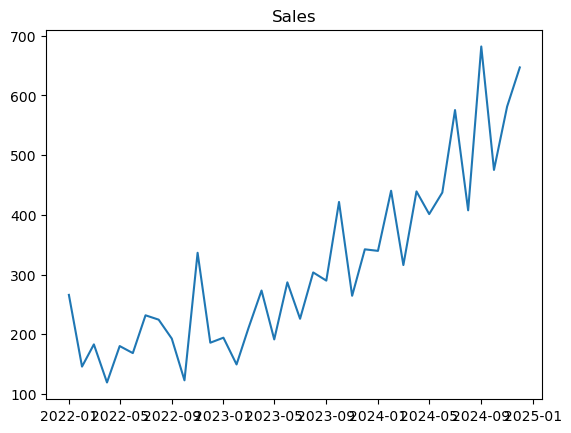

In [85]:
pt.plot(df['Sales'])
pt.title('Sales')

# AUTOCORRELATION_PLOT

<Axes: xlabel='Lag', ylabel='Autocorrelation'>

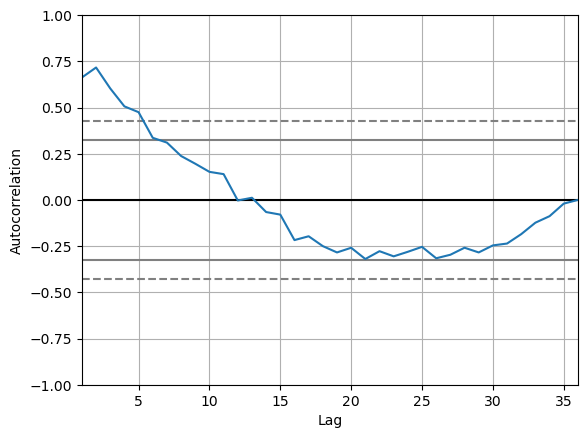

In [127]:
from pandas.plotting import autocorrelation_plot
autocorrelation_plot(df['Sales'])

<Axes: xlabel='Month'>

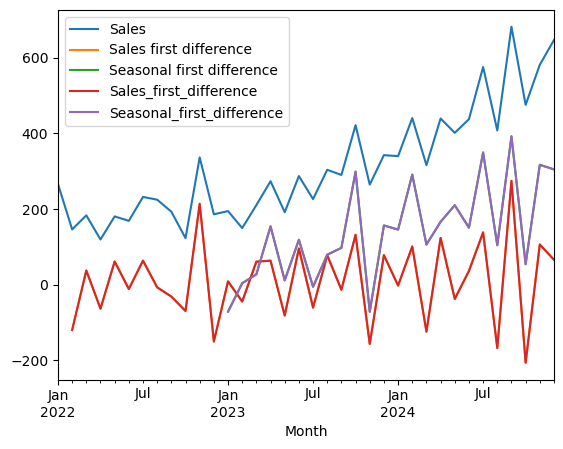

In [128]:
df.plot()

# check for stationarity

In [129]:
from statsmodels.tsa.stattools import adfuller
test_result=adfuller(df['Sales'])

In [130]:
#H0:it is non stationary
#H1:it is stationary

def adfuller_test(Sales):
    result=adfuller(Sales)
    labels=['ADF Test Statistic','p_value','#Lags Used','Number of observation Used']
    for value ,label in zip(result,labels):
        print(label+':'+str(value))
    if result[1]<=.05:
        print('strong evidence agains null hypothesis9HO), reject the null hypothesis.Data has no unit root and is stationary')
    else:
        print('Weak evidence against the null hypothesis, time series has no uni,indicating it is non stationary')


In [131]:
adfuller_test(df['Sales'])

ADF Test Statistic:3.0601420836411792
p_value:1.0
#Lags Used:10
Number of observation Used:25
Weak evidence against the null hypothesis, time series has no uni,indicating it is non stationary


In [132]:
df['Sales_first_difference']=df['Sales']-df['Sales'].shift(1)
df['Seasonal_first_difference']=df['Sales']-df['Sales'].shift(12)

In [133]:
#H0:it is non stationary
#H1:it is stationary

def adfuller_test(Sales_first_difference):
    result=adfuller(Sales_first_difference)
    labels=['ADF Test Statistic','p_value','#Lags Used','Number of observation Used']
    for value ,label in zip(result,labels):
        print(label+':'+str(value))
    if result[1]<=.05:
        print('strong evidence agains null hypothesis9HO), reject the null hypothesis.Data has no unit root and is stationary')
    else:
        print('Weak evidence against the null hypothesis, time series has no uni,indicating it is non stationary')


In [134]:
clean_data=df['Sales_first_difference'].dropna()

In [135]:
!pip install pmdarima

In [136]:

from pmdarima import auto_arima

In [156]:
model=auto_arima(clean_data,p=0,max_p=5,q=0,max_q=5,m=12)

In [157]:
print(model.summary())

                                     SARIMAX Results                                      
Dep. Variable:                                  y   No. Observations:                   35
Model:             SARIMAX(1, 0, 1)x(0, 0, 1, 12)   Log Likelihood                -194.763
Date:                            Tue, 21 Jul 2026   AIC                            399.526
Time:                                    17:57:47   BIC                            407.302
Sample:                                02-01-2022   HQIC                           402.210
                                     - 12-01-2024                                         
Covariance Type:                              opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
intercept     19.8012      4.268      4.640      0.000      11.436      28.166
ar.L1         -0.5468      0.184   

<Axes: xlabel='Lag', ylabel='Autocorrelation'>

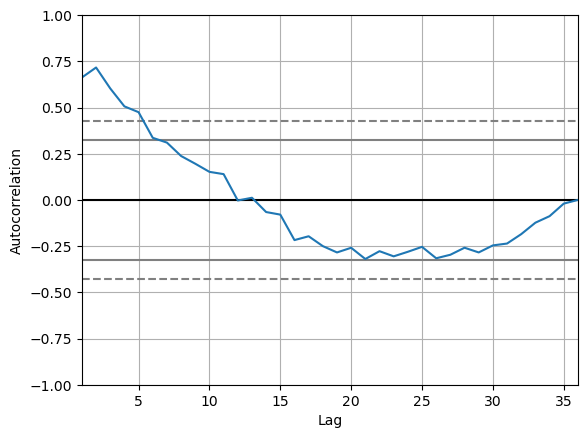

In [158]:
from pandas.plotting import autocorrelation_plot
autocorrelation_plot(df['Sales'])

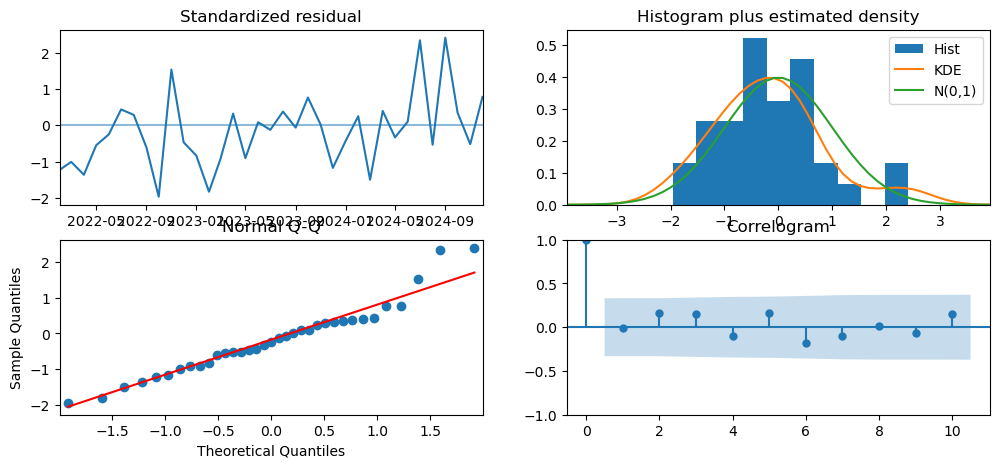

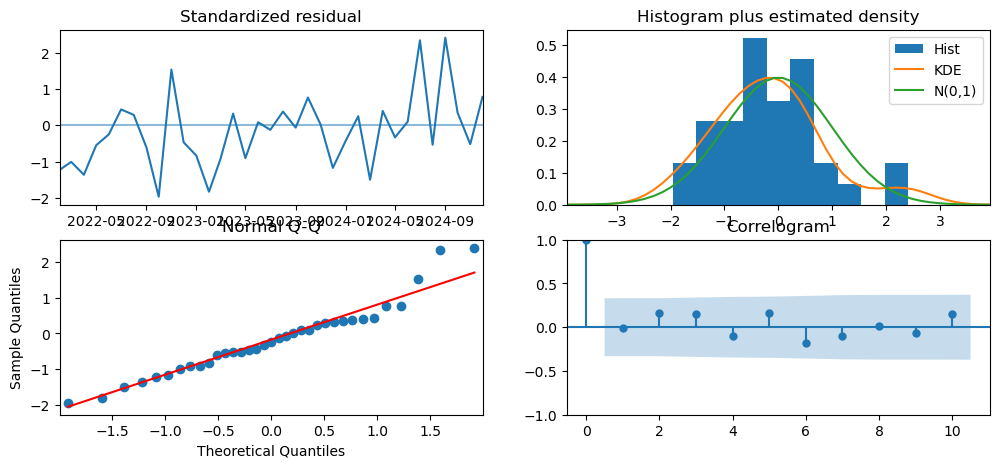

In [159]:
model.plot_diagnostics(figsize=(12,5))

In [160]:
forecast_steps=12
forecast,conf_int=model.predict(n_periods=forecast_steps,return_conf_int=True,alpha=.05)

In [161]:
print('=== FPRECAST RESULTS ===')
print('Forecasted Values (First Differences):')
print(forecast)
print('n\Confidence inervals:')
print(conf_int)

=== FPRECAST RESULTS ===
Forecasted Values (First Differences):
2025-01-01    -42.410196
2025-02-01     24.004419
2025-03-01     70.395771
2025-04-01    -62.458969
2025-05-01     74.428711
2025-06-01    -31.146993
2025-07-01    -53.105857
2025-08-01    114.131866
2025-09-01   -147.368662
2025-10-01    132.227030
2025-11-01    -25.401610
2025-12-01     -6.918325
Freq: MS, dtype: float64
n\Confidence inervals:
[[-154.23380466   69.4134128 ]
 [-135.27176343  183.28060153]
 [-100.23504785  241.02658925]
 [-236.34087582  111.42293878]
 [-100.41348878  249.27091062]
 [-206.27515248  143.98116584]
 [-228.31894121  122.10722797]
 [ -61.10497881  289.36871073]
 [-322.60717691   27.86985378]
 [ -42.99381264  307.44787292]
 [-200.55637681  149.75315655]
 [-181.84983709  168.01318695]]
